# Parte 4 · ¿Quién sigue vivo?

**Autor:** José Gregorio Coronel Colombo · Grupo 1

**Declaración de uso de IA:** se utilizó inteligencia artificial como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por el autor.

**Referencias principales**

- Fader, P. S., Hardie, B. G. S. y Lee, K. L. (2005). "Counting Your Customers" the Easy Way: An Alternative to the Pareto/NBD Model. *Marketing Science*, 24(2), 275–284.
- Batislam, E. P., Denizel, M. y Filiztekin, A. (2007). Empirical Validation and Comparison of Models for Customer Base Analysis. *International Journal of Research in Marketing*, 24(3), 201–209.

Este notebook evalúa qué tan bien el BG/NBD identifica a los clientes que vuelven a comprar en el holdout (4.1–4.5) y lo compara con el MBG/NBD (4.6). Las funciones están en `src/bgnbd.py` (`p_vivo`, `p_compra`) y `src/mbgnbd.py`. Los parámetros del BG/NBD se leen de `resultados/params_cdnow.json`, que se sobrescribe con el ajuste oficial del inciso 2.1.

In [1]:
import sys, json, os, warnings
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, brier_score_loss
from datos import cargar_cdnow, resumen_clientes
from bgnbd import p_vivo, p_compra

trans = cargar_cdnow("../data/CDNOW_sample.txt")
res = resumen_clientes(trans, "1997-09-30", "1998-06-30")
x, tx, T = res["x"].values, res["tx"].values, res["T"].values
TAU = 39  # semanas de holdout: 1 oct 1997 – 30 jun 1998

RUTA_PARAMS = "../resultados/params_cdnow.json"
if os.path.exists(RUTA_PARAMS):
    params = json.load(open(RUTA_PARAMS))
    print("Parámetros de params_cdnow.json:", params)
else:
    params = {"r": 0.243, "alpha": 4.414, "a": 0.793, "b": 2.426}
    print("Aún no existe params_cdnow.json; se usan los del artículo:", params)

Parámetros de params_cdnow.json: {'r': 0.243, 'alpha': 4.414, 'a': 0.793, 'b': 2.426}


### Verificación de P(vivo) contra `lifetimes`

$P(\text{vivo})$ se programó a mano en `p_vivo`; `lifetimes` se usa solo para comprobar que da lo mismo con los mismos parámetros.

In [2]:
from lifetimes import BetaGeoFitter

bgf = BetaGeoFitter()
bgf.params_ = pd.Series(params)

res["p_vivo"] = p_vivo(x, tx, T, params)
print("Diferencia máxima con lifetimes:",
      f"{np.abs(res['p_vivo'] - bgf.conditional_probability_alive(x, tx, T)).max():.1e}")

Diferencia máxima con lifetimes: 2.2e-16


## 4.1 · P(vivo) como clasificador de Z

$Z_i = 1$ si el cliente $i$ compró al menos una vez en el holdout ($x^*_i \ge 1$). La tasa base es la fracción de clientes con $Z_i = 1$. Se clasifica como "vivo" a quien tiene $P(\text{vivo}) \ge 0.5$.

In [3]:
res["Z"] = (res["x_star"] >= 1).astype(int)
z = res["Z"].values
tasa_base = z.mean()
print(f"Tasa base: {tasa_base:.3f} ({z.sum()} de {len(z)} clientes compraron en el holdout)")

matriz = confusion_matrix(z, res["p_vivo"] >= 0.5)
auc_p_vivo = roc_auc_score(z, res["p_vivo"])
print(f"AUC de P(vivo): {auc_p_vivo:.3f}")
pd.DataFrame(matriz,
             index=["Real: no compró (Z = 0)", "Real: compró (Z = 1)"],
             columns=["Predicho: muerto (P < 0.5)", "Predicho: vivo (P ≥ 0.5)"])

Tasa base: 0.290 (684 de 2357 clientes compraron en el holdout)
AUC de P(vivo): 0.316


,Predicho: muerto (P < 0.5),Predicho: vivo (P ≥ 0.5)
Real: no compró (Z = 0),254,1419
Real: compró (Z = 1),139,545


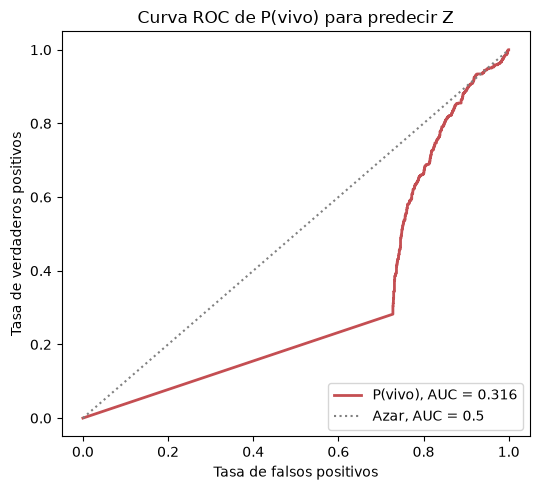

In [4]:
fpr, tpr, _ = roc_curve(z, res["p_vivo"])

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color="#C44E52", lw=2, label=f"P(vivo), AUC = {auc_p_vivo:.3f}")
ax.plot([0, 1], [0, 1], color="gray", ls=":", label="Azar, AUC = 0.5")
ax.set(title="Curva ROC de P(vivo) para predecir Z", xlabel="Tasa de falsos positivos",
       ylabel="Tasa de verdaderos positivos")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../figs/parte4_roc_p_vivo.png", dpi=150)
plt.show()

> **Pregunta 4.1 (a).** ¿Cuál es la tasa base?

Solo el 29 % de los 2 357 clientes (684) realizó al menos una compra durante las 39 semanas de holdout. El 71 % restante no volvió a comprar.

> **Pregunta 4.1 (b).** ¿Qué tan bueno es P(vivo) como clasificador de Z?

Es muy malo. Con umbral 0.5, el modelo clasifica como vivos a 1 964 clientes, de los cuales 1 419 no compraron en el holdout. Por eso acierta apenas en ≈ 34 % de los casos, muy por debajo del 71 % que se obtendría prediciendo que nadie compra. El AUC es ≈ 0.32, **menor que 0.5**: ordenar a los clientes por $P(\text{vivo})$ funciona peor que ordenarlos al azar, porque quienes reciben la probabilidad más alta tienden a ser los que *menos* compran después.

## 4.2 · ¿Por qué el resultado es tan raro?

Se separa a los clientes que no hicieron compras repetidas en la calibración ($x = 0$) del resto.

In [5]:
res["grupo"] = np.where(res["x"] == 0, "x = 0", "x ≥ 1")
pd.DataFrame({
    "clientes": res.groupby("grupo").size(),
    "P(vivo) mínima": res.groupby("grupo")["p_vivo"].min(),
    "P(vivo) promedio": res.groupby("grupo")["p_vivo"].mean(),
    "fracción que compró en el holdout": res.groupby("grupo")["Z"].mean(),
}).round(3)

,clientes,P(vivo) mínima,P(vivo) promedio,fracción que compró en el holdout
grupo,,,,
x = 0,1411,1.0,1.000,0.137
x ≥ 1,946,0.0,0.535,0.519


> **Pregunta 4.2.** ¿Cuánto vale P(vivo) para un cliente con x = 0, y por qué? ¿Qué fracción de esos clientes compró en el holdout?

Para todo cliente con $x = 0$, $P(\text{vivo}) = 1$ exactamente, porque en la fórmula desaparece el término con $\delta_{x>0}$. La razón está en el supuesto 3 del BG/NBD: el cliente solo puede morir *justo después de una compra repetida*. Un cliente que solo hizo su primera compra nunca tuvo la oportunidad de morir, así que el modelo está seguro de que sigue vivo, sin importar cuánto tiempo lleve sin comprar.

Estos clientes son el 60 % de la base (1 411) y solo el ≈ 14 % de ellos compró en el holdout, la mitad de la tasa base. Por eso P(vivo) se equivoca tanto: el grupo al que asigna la máxima probabilidad es precisamente el que menos compra, lo que explica tanto los 1 419 falsos positivos como el AUC por debajo de 0.5. Además, aun si un cliente está vivo, puede tener una $\lambda$ tan baja que no compre en 39 semanas. Estar vivo no es lo mismo que comprar.

## 4.3 · La probabilidad correcta: P(Z = 1)

**Objetivo.** Mostrar que, con $\tau = 39$ semanas de holdout,

$$P(Z = 1 \mid x, t_x, T) = P(\text{vivo} \mid x, t_x, T)\left[1 - \left(\frac{\alpha + T}{\alpha + T + \tau}\right)^{r+x}\right].$$

**Paso 1: condicionar en si el cliente está vivo en $T$.** Por probabilidad total,

$$P(Z = 1 \mid x, t_x, T) = P(\text{vivo})\,P(Z = 1 \mid \text{vivo}) + P(\text{muerto})\,P(Z = 1 \mid \text{muerto}).$$

Un cliente muerto no vuelve a comprar, así que $P(Z = 1 \mid \text{muerto}) = 0$ y solo queda el primer término.

**Paso 2: un vivo que no compra sigue vivo.** En el BG/NBD la muerte solo puede ocurrir *inmediatamente después de una compra*. Por eso, para un cliente vivo en $T$, el evento "cero compras en $(T, T + \tau]$" depende solo de su proceso de Poisson: no puede morir antes de su siguiente compra. Si $\lambda$ fuera conocida,

$$P(\text{0 compras en } \tau \mid \lambda, \text{vivo}) = e^{-\lambda\tau}.$$

**Paso 3: posterior de $\lambda$ dado que está vivo.** Si el cliente sigue vivo en $T$, su historia pertenece a la rama (a) de 1.1, cuya verosimilitud en $\lambda$ es proporcional a $\lambda^x e^{-\lambda T}$ (el factor $(1-p)^x$ no depende de $\lambda$). Multiplicando por la previa $\text{Gamma}(r, \alpha)$:

$$f(\lambda \mid \text{vivo}, x, t_x, T) \;\propto\; \lambda^x e^{-\lambda T}\cdot \lambda^{r-1}e^{-\alpha\lambda} = \lambda^{r+x-1}e^{-(\alpha+T)\lambda},$$

es decir, $\lambda \mid \text{vivo}, \text{datos} \sim \text{Gamma}(r + x,\ \alpha + T)$.

**Paso 4: mezcla gamma–Poisson.** Se integra $e^{-\lambda\tau}$ contra esa posterior:

$$P(\text{0 compras en } \tau \mid \text{vivo}) = \int_0^\infty e^{-\lambda\tau}\,\frac{(\alpha+T)^{r+x}\lambda^{r+x-1}e^{-(\alpha+T)\lambda}}{\Gamma(r+x)}\,d\lambda = \frac{(\alpha+T)^{r+x}}{\Gamma(r+x)}\cdot\frac{\Gamma(r+x)}{(\alpha+T+\tau)^{r+x}} = \left(\frac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}.$$

Es la misma integral de 1.2, con $\alpha + T + \tau$ en lugar de $\alpha + s$.

**Resultado.** $P(Z = 1 \mid \text{vivo}) = 1 - \left(\frac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}$. Al sustituir en el paso 1 se obtiene la fórmula. $\blacksquare$

**Para una diapositiva:** $P(Z=1) = \underbrace{P(\text{vivo})}_{\text{¿sigue activo?}}\times\underbrace{\left[1 - \left(\tfrac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}\right]}_{\text{¿compra en } \tau \text{ si está activo?}}$. Para $x = 0$ el primer factor vale 1, pero el segundo es pequeño porque la posterior $\text{Gamma}(r, \alpha + T)$ concentra $\lambda$ cerca de 0: un cliente que lleva $T$ semanas sin repetir probablemente compra muy poco.

La fórmula está implementada en `p_compra(tau, x, tx, T, params)` de `src/bgnbd.py`. La siguiente celda muestra los dos factores por grupo.

In [6]:
res["p_compra"] = p_compra(TAU, x, tx, T, params)
res.groupby("grupo")[["p_vivo", "p_compra", "Z"]].mean().round(3).rename(columns={
    "p_vivo": "P(vivo) promedio", "p_compra": "P(Z = 1) promedio", "Z": "fracción que compró"})

,P(vivo) promedio,P(Z = 1) promedio,fracción que compró
grupo,,,
x = 0,1.000,0.161,0.137
x ≥ 1,0.535,0.413,0.519
